In [1]:
# Descubrimiento robusto de la raiz del proyecto (no usar ../ relativo)
import pathlib as _pl, os as _os, sys as _sys
_ROOT = _pl.Path().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
_os.chdir(_ROOT)
if str(_ROOT) not in _sys.path:
    _sys.path.insert(0, str(_ROOT))
if str(_ROOT / "src") not in _sys.path:
    _sys.path.insert(0, str(_ROOT / "src"))
print("cwd:", _os.getcwd())


cwd: C:\Users\mikel\Desktop\Pruebas\nasa


# 03 · Features secuenciales — ¿el reloj (`cyc_norm`) ayuda o es trampa?

Parte 2 de 3. Mismo código que la sección 6 del original.

**Requisito:** ninguno. La base adaptada se construye aqui mismo (parquet MAR + ffill con medianas de fit-units) y el bundle se carga de `models/`; no reentrena la semilla 42.


**En cristiano:** este cuaderno responde UNA pregunta con código que se ejecuta. Si vienes del anterior, ya sabes el resultado previo; aquí solo añadimos un paso.


In [2]:
# 2. Alias estilo clase (solo lectura: no entrenan, no cambian numeros).
#    evaluar_clase/mostrar_clase ya vienen de viz (ver src/ds02_rul/viz.py).
print("[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)")


[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)


In [3]:
# Puente C: base adaptada (MAR T30 + ffill) + bundle desplegado en models/.
# Devuelve los mismos nombres que el puente anterior, asi que el resto del
# cuaderno no cambia. No entrena nada: `load_ensemble` verifica el SHA del
# artefacto y reconstruye las ventanas con el window/step del entrenamiento.
import os as _os
import pathlib as _pl
import sys as _sys

# Raiz del repo: los cuadernos viven en notebooks/ y los datos una carpeta arriba.
# La celda se busca la raiz sola, asi no depende del orden de ejecucion.
_ROOT = _pl.Path.cwd().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
_os.chdir(_ROOT)
for _p in (str(_ROOT), str(_ROOT / "src")):
    if _p not in _sys.path:
        _sys.path.insert(0, _p)

from src.clase.puente_c import puente_c

P = puente_c()
raw, dev, test, prep = P["raw"], P["dev"], P["test"], P["prep"]
fit_idx, hold_idx, dev_units = P["fit_idx"], P["hold_idx"], P["dev_units"]
result = P["result"]
bilstm, lgbm = result["bilstm"], result["lgbm"]
p_lstm_hold, p_lstm_test = result["p_lstm_hold"], result["p_lstm_test"]
p_lgb_hold, p_lgb_test = result["p_lgb_hold"], result["p_lgb_test"]
FIT_UNITS = [2.0, 5.0, 10.0, 18.0, 20.0]
HOLDOUT_UNITS = [16.0]
TEST_UNITS = [11.0, 14.0, 15.0]
print("[PUENTE C OK] dev", dev["X_seq"].shape, "| test", test["X_seq"].shape,
      "| particiones", P["particiones"])


[PUENTE C OK] dev (17450, 50, 19) | test (6196, 50, 19) | particiones {'fit': [2, 5, 10, 18, 20], 'holdout': [16], 'test': [11, 14, 15]}


### Glosario en 30 segundos (estilo clase)

| Nombre | Qué es | Dónde vive |
|---|---|---|
| `WINDOW=50` | 50 lecturas seguidas = 1 ventana | `features.py:build_windows` |
| `STEP 3/2` | Separación entre ventanas (train/test) | `pipeline.py:run_seed` |
| `BETA` | Cuánto manda el meta (mediana OOF, `1.0`) | `stacking.py:select_beta_grouped` |
| `EMA5` | Suavizado causal por motor | `smoothing.py:causal_ema_by_unit` |
| `L_inf` | Peor caso de la banda 90% | `conformal.py:apply_conformal` |
| `OOF` | Cada ventana la puntúa otro motor | `pipeline.py:oof_base_predictions` |
| `macro` | Cada motor pesa 1/3 | `metrics.py:macro_rmse` |


**Como leer (antes de la tabla de ablacion, test 11/14/15, semilla 42, 4 variantes).** Cada fila es una regla de construir la entrada (reloj si/no, linea base si/no) y cada columna un modelo: BiLSTM lee la secuencia, LGBM resume la ventana. RMSE y NASA Score: menos es mejor. La tabla `pivot` es la lectura rapida; la tabla larga de abajo es el detalle completo.


In [4]:
PRIMARY_SEED=42; WINDOW_SIZE=50; STEP_TRAIN=3; STEP_TEST=2
# Ablación en vivo: ¿cuánto cuesta quitar el reloj? (4 variantes, 1 semilla=42)
# Cada variante re-entrena LGBM+BiLSTM con el mismo protocolo; lo barato tarda segundos, lo caro (BiLSTM) manda en el tiempo.
from ds02_rul.pipeline import ablation_table
abl = ablation_table(raw, seeds=(PRIMARY_SEED,), window=WINDOW_SIZE,
                    step_train=STEP_TRAIN, step_test=STEP_TEST, epochs=22,
                    fit_units=FIT_UNITS, holdout_units=HOLDOUT_UNITS,
                    include_bilstm=True)
print('Ablación medida sobre test 11/14/15 (semilla 42)')
print()
print(abl.pivot(index='variant', columns='model', values=['RMSE','NASA_Score']).round(3).to_string())
print()
print(abl.to_string(index=False))



Ablación medida sobre test 11/14/15 (semilla 42)

                                RMSE                   NASA_Score                   
model                         BiLSTM BiLSTM+EMA   LGBM     BiLSTM BiLSTM+EMA    LGBM
variant                                                                             
cyc_norm OFF                   6.563      6.499  6.297     3711.6     3656.8  4600.9
cyc_norm OFF + baseline delta  6.394      6.324  8.765     3642.3     3579.8  8450.0
cyc_norm ON  (baseline)        5.796      5.771  7.067     3910.9     3892.4  5731.3
cyc_norm ON  + baseline delta  5.512      5.490  8.547     3601.2     3586.6  8037.9

                      variant      model  RMSE   MAE     R2  NASA_Score
      cyc_norm ON  (baseline)       LGBM 7.067 5.545 0.8570      5731.3
      cyc_norm ON  (baseline)     BiLSTM 5.796 4.370 0.9038      3910.9
      cyc_norm ON  (baseline) BiLSTM+EMA 5.771 4.352 0.9046      3892.4
                 cyc_norm OFF       LGBM 6.297 4.953 0.8864      

**Que vemos (ablacion medida, semilla 42).** BiLSTM empeora sin reloj: 5.796 (ON) a 6.563 (OFF); con linea base delta se queda en 6.394, que recupera parte pero no todo. LGBM, en cambio, mejora sin reloj (6.297 OFF frente a 7.067 ON) y con la linea base delta se hunde a 8.765. Conclusion: el reloj ayuda a la rama que lee la secuencia (BiLSTM) y no al resumen tabular (LGBM): el reloj ayuda a la secuencia, no al resumen.


## Ablación de `cyc_norm` — medida, no afirmada

Hay un número que circula en la documentación del proyecto —*13,349* ciclos de
costo por quitar el contador— y no sirve aquí: venía de la iteración 3, que tenía
78 características, ningún ciclo acumulado **y ninguna residualización**: otro
diseño, no este menos una columna. Así que la tabla de abajo se calcula acá, y lo
que diga es la respuesta.

La alternativa al contador de ciclos es una **línea base sana por motor**: la
media del vector de sensores residualizado en los tres primeros ciclos de ese
motor, restada del resto de su vida. Es causal (solo lee la vida temprana de ese
mismo motor) y es lo que una flota real registraría en la puesta en marcha.


**Ojo, esto no es el hibrido final.** Esta tabla compara piezas sueltas para decidir si el reloj entra; el numero final del bundle desplegado (4.338, con meta y EMA5) se mide en el 04. Y la `pivot` es la lectura, la tabla larga el detalle.


model                          BiLSTM  BiLSTM+EMA   LGBM
variant                                                 
cyc_norm OFF                    6.563       6.499  6.297
cyc_norm OFF + baseline delta   6.394       6.324  8.765
cyc_norm ON (baseline)          5.796       5.771  7.067
cyc_norm ON + baseline delta    5.512       5.490  8.547
<IPython.core.display.Image object>


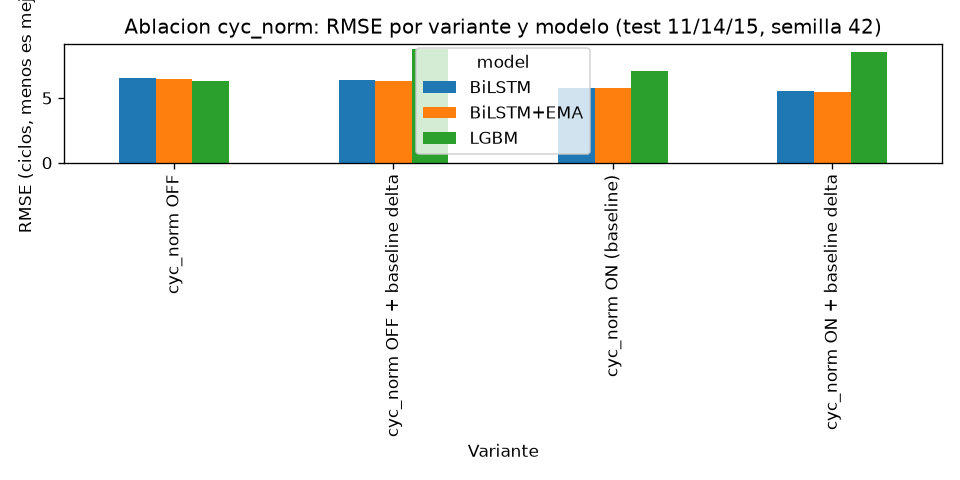

In [5]:
# Figura BARATA (nueva): barras RMSE por variante desde la tabla de ablacion YA calculada.
# NO reentrena ni llama ablation_table: reutiliza `abl` en memoria si existe; si no, la copia
# literal de la salida impresa de la celda de ablacion (test 11/14/15, semilla 42).
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import pandas as pd

if 'abl' in globals():
    _abl = abl
else:
    _abl = pd.DataFrame([
        {'variant': 'cyc_norm OFF', 'model': 'BiLSTM', 'RMSE': 6.563},
        {'variant': 'cyc_norm OFF', 'model': 'BiLSTM+EMA', 'RMSE': 6.499},
        {'variant': 'cyc_norm OFF', 'model': 'LGBM', 'RMSE': 6.297},
        {'variant': 'cyc_norm OFF + baseline delta', 'model': 'BiLSTM', 'RMSE': 6.394},
        {'variant': 'cyc_norm OFF + baseline delta', 'model': 'BiLSTM+EMA', 'RMSE': 6.324},
        {'variant': 'cyc_norm OFF + baseline delta', 'model': 'LGBM', 'RMSE': 8.765},
        {'variant': 'cyc_norm ON (baseline)', 'model': 'BiLSTM', 'RMSE': 5.796},
        {'variant': 'cyc_norm ON (baseline)', 'model': 'BiLSTM+EMA', 'RMSE': 5.771},
        {'variant': 'cyc_norm ON (baseline)', 'model': 'LGBM', 'RMSE': 7.067},
        {'variant': 'cyc_norm ON + baseline delta', 'model': 'BiLSTM', 'RMSE': 5.512},
        {'variant': 'cyc_norm ON + baseline delta', 'model': 'BiLSTM+EMA', 'RMSE': 5.490},
        {'variant': 'cyc_norm ON + baseline delta', 'model': 'LGBM', 'RMSE': 8.547},
    ])
_piv = _abl.pivot(index='variant', columns='model', values='RMSE')
_orden = ['cyc_norm OFF', 'cyc_norm OFF + baseline delta', 'cyc_norm ON (baseline)', 'cyc_norm ON + baseline delta']
_piv = _piv.reindex(_orden)
_fig, _ax = plt.subplots(figsize=(8, 4))
_piv.plot.bar(ax=_ax)
_ax.set_title('Ablacion cyc_norm: RMSE por variante y modelo (test 11/14/15, semilla 42)')
_ax.set_xlabel('Variante')
_ax.set_ylabel('RMSE (ciclos, menos es mejor)')
_fig.tight_layout()
_fig.savefig('resultados/ablacion_cycnorm_rmse.png', dpi=120)
plt.close(_fig)
print(_piv.round(3).to_string())
from IPython.display import Image, display
display(Image('resultados/ablacion_cycnorm_rmse.png'))



## Siguiente
Continúa en `04_arquitectura_bilstm_oof.ipynb`.
